# MovieLens 32M — EDA
Рекомендательная система фильмов · ML-трек · Команда 129.

Цель анализа — подготовить данные для персональных top-10 рекомендаций. Рейтинг — явная оценка; для ранжирования положительным считаем рейтинг ≥ 4 и проверяем чувствительность к порогу.

[Данные и условия использования](https://files.grouplens.org/datasets/movielens/ml-32m-README.html) · [Требования чекпойнта](https://docs.google.com/document/d/1Izow1n6RTf-iP6MEXE3zVH9i5-gBoFUr4uJvCLKhh1U/edit).

Основные статистики рассчитаны по всем 32 000 204 оценкам. Только попарный анализ использует 200 000 validation-событий, scatter matrix — до 3 000 полных строк, seed=42. Идентификаторы и внешние ссылки — ключи, не числовые предикторы. Теги используются с учётом времени их появления.


## 0. Подготовка данных

Загружаем таблицы для анализа.

In [1]:
# При необходимости: %pip install pandas matplotlib requests
from pathlib import Path
import hashlib, zipfile
import requests
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True})
pd.set_option('display.max_columns', 20)
DATA = Path('data'); DATA.mkdir(exist_ok=True)
URL = 'https://files.grouplens.org/datasets/movielens/ml-32m.zip'
archive = DATA / 'ml-32m.zip'
if not archive.exists():
    temporary = archive.with_suffix('.part')
    with requests.get(URL, stream=True, timeout=(30, 180)) as r:
        r.raise_for_status()
        with temporary.open('wb') as f:
            for chunk in r.iter_content(1024 * 1024): f.write(chunk)
    temporary.replace(archive)
with zipfile.ZipFile(archive) as z:
    for filename in ['ratings.csv', 'movies.csv', 'tags.csv', 'links.csv', 'README.txt']:
        target = DATA / 'ml-32m' / filename
        if not target.exists(): z.extract('ml-32m/' + filename, DATA)
digest = hashlib.sha256()
with archive.open('rb') as f:
    for block in iter(lambda: f.read(1024*1024), b''): digest.update(block)
print('Archive SHA256:', digest.hexdigest())
print('Pandas version:', pd.__version__)
ratings = pd.read_csv(DATA/'ml-32m/ratings.csv', dtype={'userId':'int32','movieId':'int32','rating':'float32','timestamp':'int64'})
movies = pd.read_csv(DATA/'ml-32m/movies.csv')
tags = pd.read_csv(DATA/'ml-32m/tags.csv', keep_default_na=False)
tags['tag_clean'] = tags['tag'].str.strip()
links = pd.read_csv(DATA/'ml-32m/links.csv')
print({k: len(v) for k,v in {'ratings': ratings, 'movies': movies, 'tags': tags, 'links': links}.items()})
expected_md5 = {'ratings.csv': 'cf12b74f9ad4b94a011f079e26d4270a',
                'movies.csv': '0df90835c19151f9d819d0822e190797',
                'tags.csv': '963bf4fa4de6b8901868fddd3eb54567',
                'links.csv': '8f033867bcb4e6be8792b21468b4fa6e'}
for filename, expected in expected_md5.items():
    checksum = hashlib.md5()
    with (DATA/'ml-32m'/filename).open('rb') as file:
        for block in iter(lambda: file.read(1024 * 1024), b''):
            checksum.update(block)
    assert checksum.hexdigest() == expected, filename
print('All four CSV checksums match the dataset README.')


Archive SHA256: e4a68655d7386b8f95f2f2424b2ff975dfdd15ffd59e0d864a14dca43e99d6ee
Pandas version: 2.3.3


{'ratings': 32000204, 'movies': 87585, 'tags': 2000072, 'links': 87585}


All four CSV checksums match the dataset README.


**Вывод.** 32 000 204 оценки, 87 585 объектов каталога, 2 000 072 тега. Контрольные суммы CSV совпадают с описанием источника. Записи отражают оценки, а не все просмотры; отсутствие оценки не означает неприязнь.

## 1. Статистики исходных признаков

Рассчитываем числовые и категориальные статистики; идентификаторы рассматриваем только как ключи.

In [2]:
raw_tables = {
    'ratings': ratings,
    'movies': movies,
    'tags': tags[['userId','movieId','tag','timestamp']],
    'links': links
}
for name, frame in raw_tables.items():
    print(name)
    display(frame.describe(include='all').T)
    display(pd.DataFrame({'dtype':frame.dtypes.astype(str), 'unique':frame.nunique(dropna=False)}))


ratings


,count,mean,std,min,25%,50%,75%,max
userId,32000204.0,1.002785e+05,5.794905e+04,1.0,5.005300e+04,1.002970e+05,1.504510e+05,2.009480e+05
movieId,32000204.0,2.931861e+04,5.095816e+04,1.0,1.233000e+03,3.452000e+03,4.419900e+04,2.927570e+05
rating,32000204.0,3.540396e+00,1.058986e+00,0.5,3.000000e+00,3.500000e+00,4.000000e+00,5.000000e+00
timestamp,32000204.0,1.275241e+09,2.561630e+08,789652004.0,1.051012e+09,1.272622e+09,1.503158e+09,1.697164e+09


,dtype,unique
userId,int32,200948
movieId,int32,84432
rating,float32,10
timestamp,int64,25976523


movies


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
movieId,87585.0,NaN,NaN,NaN,157651.365519,79013.402099,1.0,112657.0,165741.0,213203.0,292757.0
title,87585,87382,Alone (2020),4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genres,87585,1798,Drama,12443,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,dtype,unique
movieId,int64,87585
title,object,87382
genres,object,1798


... (2 outputs left out)

,dtype,unique
userId,int64,15848
movieId,int64,51323
tag,object,140981
timestamp,int64,1291250


links


,count,mean,std,min,25%,50%,75%,max
movieId,87585.0,1.576514e+05,7.901340e+04,1.0,112657.0,165741.0,213203.0,292757.0
imdbId,87585.0,2.792840e+06,4.278866e+06,1.0,94642.0,492996.0,3877296.0,29081098.0
tmdbId,87461.0,2.413823e+05,2.471467e+05,2.0,46836.0,139272.0,381693.0,1186337.0


,dtype,unique
movieId,int64,87585
imdbId,int64,87585
tmdbId,float64,87426


**Вывод.** Числовые и категориальные статистики рассчитаны для всех четырёх таблиц. Шкала rating — 0,5–5; userId, movieId, imdbId и tmdbId используются для связей, их числовые средние не интерпретируются.

## 2. Схема и качество

Ищем ошибки, которые могут исказить обучение.

In [3]:
for name, frame in [('ratings', ratings), ('movies', movies), ('tags', tags), ('links', links)]:
    print(name); display(frame.head(3)); display(frame.isna().sum().to_frame('missing'))
quality = pd.Series({
    'duplicate_rating_rows': int(ratings.duplicated().sum()),
    'duplicate_user_movie': int(ratings.duplicated(['userId','movieId']).sum()),
    'duplicate_movie_keys': int(movies.movieId.duplicated().sum()),
    'ratings_without_metadata': int((~ratings.movieId.isin(movies.movieId)).sum()),
    'invalid_ratings': int((~ratings.rating.isin([0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5])).sum()),
    'missing_genres': int(movies.genres.eq('(no genres listed)').sum()),
    'blank_tag_text': int(tags['tag_clean'].eq('').sum())})
display(quality.to_frame('count'))
assert quality['invalid_ratings'] == 0
assert ratings[['userId','movieId','timestamp','rating']].notna().all().all()
assert quality['duplicate_movie_keys'] == 0

ratings


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976


,missing
userId,0
movieId,0
rating,0
timestamp,0


movies


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


,missing
movieId,0
title,0
genres,0


... (3 outputs left out)

links


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0


,missing
movieId,0
imdbId,0
tmdbId,124


,count
duplicate_rating_rows,0
duplicate_user_movie,0
duplicate_movie_keys,0
ratings_without_metadata,0
invalid_ratings,0
missing_genres,7080
blank_tag_text,6


**Вывод.** Дубликатов оценок, повторных пар пользователь–фильм и оценок вне шкалы нет. У 7 080 объектов не указан жанр, у 124 нет tmdbId. Найдено 6 пустых или пробельных тегов; NA и null сохранены как текст.

## 3. Плотность, активность и длинный хвост

Оцениваем объём истории и концентрацию популярности.

,value
ratings,3.200020e+07
users,2.009480e+05
rated_movies,8.443200e+04
catalog_movies,8.758500e+04
density,1.886088e-03
catalog_without_ratings,3.153000e+03
top_1pct_movies_rating_share,5.487858e-01
users_with_under_20_ratings_share,0.000000e+00
movies_with_under_5_ratings_share,4.802445e-01


,ratings_per_user,ratings_per_movie
count,200948.000000,84432.000000
mean,159.246193,379.005638
std,282.025462,2592.439791
min,20.000000,1.000000
50%,73.000000,5.000000
90%,364.000000,248.900000
99%,1290.000000,9263.140000
max,33332.000000,102929.000000


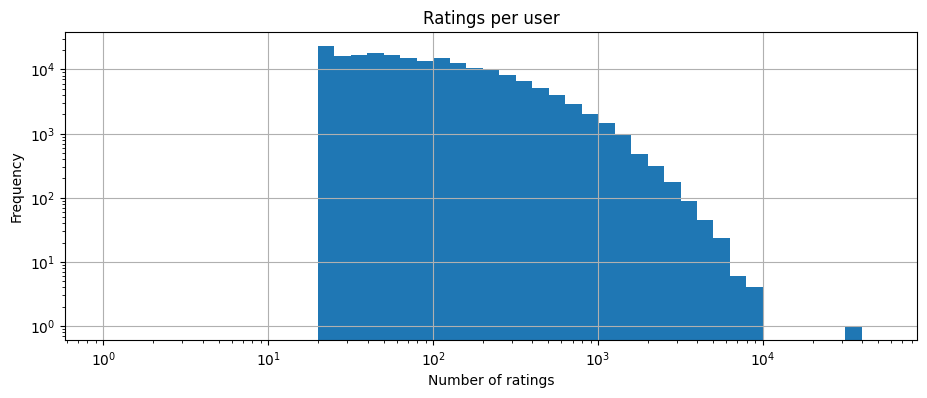

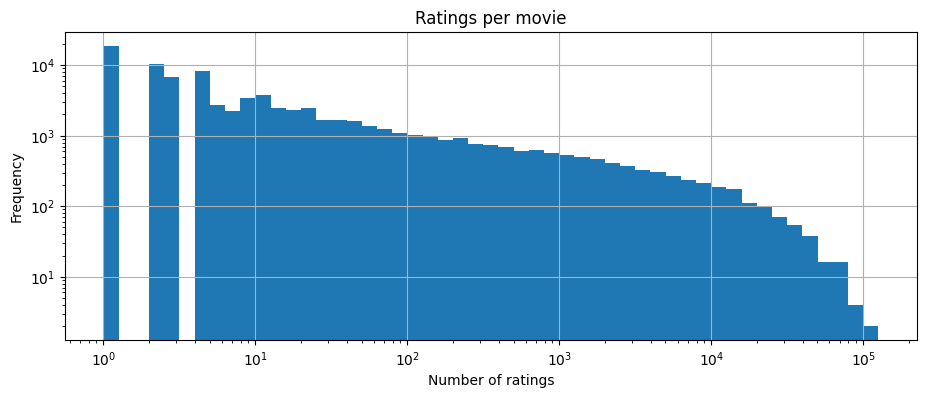

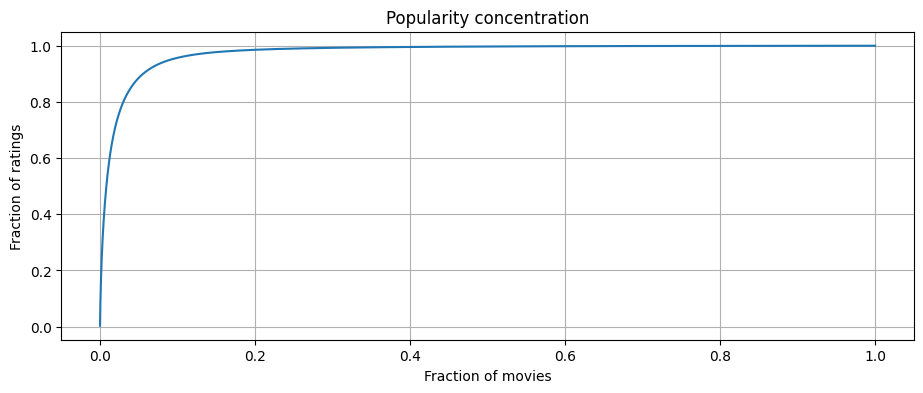

In [4]:
user_counts = ratings.groupby('userId').size()
item_counts = ratings.groupby('movieId').size()
unique_pairs = len(ratings.drop_duplicates(['userId','movieId']))
top_n = max(1, (len(item_counts) + 99) // 100)
summary = pd.Series({
    'ratings': len(ratings), 'users': len(user_counts), 'rated_movies': len(item_counts),
    'catalog_movies': len(movies), 'density': unique_pairs/(len(user_counts)*len(item_counts)),
    'catalog_without_ratings': int((~movies.movieId.isin(item_counts.index)).sum()),
    'top_1pct_movies_rating_share': item_counts.nlargest(top_n).sum()/len(ratings),
    'users_with_under_20_ratings_share': user_counts.lt(20).mean(),
    'movies_with_under_5_ratings_share': item_counts.lt(5).mean()})
display(summary.to_frame('value'))
display(pd.DataFrame({'ratings_per_user': user_counts.describe(percentiles=[.5,.9,.99]), 'ratings_per_movie': item_counts.describe(percentiles=[.5,.9,.99])}))
# Pandas строит графики напрямую из Series и DataFrame.
user_counts.plot.hist(bins=[10 ** (i / 10) for i in range(48)], logx=True, logy=True,
                      title='Ratings per user', xlabel='Number of ratings')
plt.show()
item_counts.plot.hist(bins=[10 ** (i / 10) for i in range(52)], logx=True, logy=True,
                      title='Ratings per movie', xlabel='Number of ratings')
plt.show()
popularity = item_counts.sort_values(ascending=False).reset_index(drop=True).to_frame('ratings')
popularity['movie_share'] = (popularity.index.to_series() + 1) / len(popularity)
popularity['rating_share'] = popularity['ratings'].cumsum() / ratings.shape[0]
popularity.plot(x='movie_share', y='rating_share', legend=False,
                title='Popularity concentration', xlabel='Fraction of movies', ylabel='Fraction of ratings')
plt.show()


**Вывод.** Разреженность — 99,81%. 1% оценённых фильмов собирает 54,88% оценок; у 48,02% фильмов меньше пяти оценок. В каталоге 3 153 объекта без оценок. Все пользователи отобраны с минимум 20 оценками в полном наборе; это ограничение выборки.

## 4. Пропуски и подготовка данных

Считаем доли пропусков и проверяем связь отсутствующих жанров с покрытием каталога; создаём очищенные представления. Пропусками считаем NaN, пустые строки и маркер отсутствующего жанра; неизвлечённый год учитываем отдельно.

In [5]:
missing_rows = []
missing_totals = []
for name, frame in raw_tables.items():
    raw_null = frame.isna()
    semantic_null = raw_null.copy()
    for column in frame.select_dtypes(include='object').columns:
        semantic_null[column] = semantic_null[column] | frame[column].str.strip().eq('')
    if name == 'movies':
        semantic_null['genres'] = semantic_null['genres'] | frame['genres'].eq('(no genres listed)')
    table = pd.DataFrame({
        'raw_null_count': raw_null.sum(),
        'missing_count': semantic_null.sum(),
        'missing_pct': semantic_null.mean() * 100
    })
    table.index.name = 'column'
    missing_rows.append(table.assign(table=name).reset_index())
    missing_totals.append({'table':name, 'cells':frame.size,
                           'raw_null_count':int(raw_null.sum().sum()),
                           'missing_count':int(semantic_null.sum().sum())})
missing_report = pd.concat(missing_rows, ignore_index=True).set_index(['table','column'])
missing_total = pd.DataFrame(missing_totals).set_index('table')
missing_total['missing_pct'] = missing_total['missing_count'] / missing_total['cells'] * 100
display(missing_report)
display(missing_total)
global_missing_pct = missing_total['missing_count'].sum() / missing_total['cells'].sum() * 100
print('Missing cells across original tables, %:', global_missing_pct)

movies_clean = movies.copy()
movies_clean['genre_missing'] = movies_clean['genres'].eq('(no genres listed)')
movies_clean['genres'] = movies_clean['genres'].replace('(no genres listed)', 'Unknown')
movies_clean['release_year'] = pd.to_numeric(
    movies_clean['title'].str.extract(r'\((\d{4})\)$', expand=False), errors='coerce').astype('Int64')
movies_clean['year_missing'] = movies_clean['release_year'].isna()
tags_clean = tags.loc[tags['tag_clean'].ne(''), ['userId','movieId','tag_clean','timestamp']].rename(columns={'tag_clean':'tag'}).copy()
links_clean = links.copy()
links_clean['tmdbId'] = links_clean['tmdbId'].astype('Int64')
print('Unparsed release year:', movies_clean['year_missing'].sum(),
      'share, %:', movies_clean['year_missing'].mean()*100)
print('Blank tags removed:', len(tags)-len(tags_clean))

coverage = movies_clean.assign(
    rating_count=movies_clean['movieId'].map(item_counts).fillna(0),
    has_tag=movies_clean['movieId'].isin(tags_clean['movieId']))
missing_genre_comparison = coverage.groupby('genre_missing').agg(
    movies=('movieId','size'), median_rating_count=('rating_count','median'),
    unrated_share=('rating_count',lambda x:x.eq(0).mean()), tag_coverage=('has_tag','mean'))
display(missing_genre_comparison)
assert tags_clean['tag'].str.strip().ne('').all()
assert len(movies_clean) == len(movies)


raw_null_count  missing_count  missing_pct
table   column                                               
ratings userId                  0              0     0.000000
        movieId                 0              0     0.000000
        rating                  0              0     0.000000
        timestamp               0              0     0.000000
movies  movieId                 0              0     0.000000
        title                   0              0     0.000000
        genres                  0           7080     8.083576
tags    userId                  0              0     0.000000
        movieId                 0              0     0.000000
        tag                     0              6     0.000300
        timestamp               0              0     0.000000
links   movieId                 0              0     0.000000
        imdbId                  0              0     0.000000
        tmdbId                124            124     0.141577

,cells,raw_null_count,missing_count,missing_pct
table,,,,
ratings,128000816,0,0,0.000000
movies,262755,0,7080,2.694525
tags,8000288,0,6,0.000075
links,262755,124,124,0.047192


Missing cells across original tables, %: 0.005281021618246534


Unparsed release year: 771 share, %: 0.8802877205000855
Blank tags removed: 6


,movies,median_rating_count,unrated_share,tag_coverage
genre_missing,,,,
False,80505,5.0,0.032644,0.604472
True,7080,2.0,0.074153,0.375706


**Вывод.** Смысловые пропуски занимают 0.00528% ячеек исходных таблиц: жанр отсутствует у 8,08% объектов, tmdbId — у 0,14%. У объектов без жанра медиана оценок 2 против 5: это согласуется с гипотезой меньшего покрытия редких объектов, но не устанавливает причину. Удалены 6 пустых тегов; неизвестный жанр заменён на Unknown. Неизвлечённый год и отсутствующий tmdbId оставлены пустыми: подстановка среднего года или чужого ID исказила бы данные. Для года добавлен индикатор пропуска; оценки сохранены.

## 5. Проверка допустимых значений

Проверяем шкалу, ключи, жанры и даты; подозрительные значения отделяем от отсутствующих.

In [6]:
allowed_genres = {'Action','Adventure','Animation','Children','Comedy','Crime',
                  'Documentary','Drama','Fantasy','Film-Noir','Horror','IMAX','Musical',
                  'Mystery','Romance','Sci-Fi','Thriller','War','Western','(no genres listed)'}
source_start = int(pd.Timestamp('1995-01-09', tz='UTC').timestamp())
source_end = int(pd.Timestamp('2023-10-14', tz='UTC').timestamp())
value_checks = pd.Series({
    'rating_outside_scale': (~ratings['rating'].isin([.5,1,1.5,2,2.5,3,3.5,4,4.5,5])).sum(),
    'nonpositive_rating_userId': ratings['userId'].le(0).sum(),
    'nonpositive_rating_movieId': ratings['movieId'].le(0).sum(),
    'nonpositive_catalog_movieId': movies['movieId'].le(0).sum(),
    'nonpositive_tag_userId': tags['userId'].le(0).sum(),
    'nonpositive_tag_movieId': tags['movieId'].le(0).sum(),
    'nonpositive_imdbId': links['imdbId'].le(0).sum(),
    'nonpositive_tmdbId': links['tmdbId'].dropna().le(0).sum(),
    'rating_timestamp_outside_source_period': (~ratings['timestamp'].between(source_start,source_end-1)).sum(),
    'tag_timestamp_outside_source_period': (~tags['timestamp'].between(source_start,source_end-1)).sum(),
    'year_outside_1800_2023': (~movies_clean['release_year'].dropna().between(1800,2023)).sum(),
    'unknown_genre_tokens': (~movies['genres'].str.split('|').explode().isin(allowed_genres)).sum()
})
display(value_checks.to_frame('flagged_count'))
print('Parsed release-year range:', movies_clean['release_year'].min(), movies_clean['release_year'].max())
# Даты проверяются по периоду источника, годы - как флаги для ручной проверки.
assert value_checks.eq(0).all(), 'Inspect flagged values before preparing model data.'
ratings_clean = ratings


,flagged_count
rating_outside_scale,0
nonpositive_rating_userId,0
nonpositive_rating_movieId,0
nonpositive_catalog_movieId,0
nonpositive_tag_userId,0
nonpositive_tag_movieId,0
nonpositive_imdbId,0
nonpositive_tmdbId,0
rating_timestamp_outside_source_period,0
tag_timestamp_outside_source_period,0


Parsed release-year range: 1874 2023


**Вывод.** Ошибок по заданным проверкам не найдено; извлечённые годы — 1874–2023. Удаление оценок не требуется. Неизвестный год остаётся пропуском; повторные внешние идентификаторы проверяются отдельно и не используются как уникальные ключи.

## 6. Выбросы и экстремальная активность

Отмечаем значения за границами 1,5 IQR и определяем, являются ли они ошибками.

In [7]:
outlier_rows = []
for name, values in [('ratings_per_user',user_counts), ('ratings_per_movie',item_counts), ('rating',ratings['rating'])]:
    q1, q3 = values.quantile([.25,.75])
    iqr = q3-q1
    lower, upper = q1-1.5*iqr, q3+1.5*iqr
    flags = values.lt(lower) | values.gt(upper)
    outlier_rows.append({'feature':name, 'q1':q1, 'q3':q3, 'lower':lower, 'upper':upper,
                         'flagged':int(flags.sum()), 'flagged_pct':flags.mean()*100,
                         'minimum':values.min(), 'maximum':values.max()})
outlier_report = pd.DataFrame(outlier_rows).set_index('feature')
display(outlier_report)
display(user_counts.nlargest(10).to_frame('ratings_per_user'))
display(item_counts.nlargest(10).to_frame('ratings_per_movie').join(movies.set_index('movieId')['title']))
# Валидные крайние значения сохраняются; IQR не является проверкой достоверности.
print('Ratings removed or clipped:', 0)


,q1,q3,lower,upper,flagged,flagged_pct,minimum,maximum
feature,,,,,,,,
ratings_per_user,36.0,167.0,-160.5,363.5,20109,10.007067,20.0,33332.0
ratings_per_movie,2.0,25.0,-32.5,59.5,14884,17.628387,1.0,102929.0
rating,3.0,4.0,1.5,5.5,1471807,4.599368,0.5,5.0


,ratings_per_user
userId,
175325,33332
17035,9577
55653,9178
123465,9044
171795,9016
10202,7748
198515,7594
49305,7488
22744,7372


,ratings_per_movie,title
movieId,,
318,102929,"Shawshank Redemption, The (1994)"
356,100296,Forrest Gump (1994)
296,98409,Pulp Fiction (1994)
2571,93808,"Matrix, The (1999)"
593,90330,"Silence of the Lambs, The (1991)"
260,85010,Star Wars: Episode IV - A New Hope (1977)
2959,77332,Fight Club (1999)
480,75233,Jurassic Park (1993)
527,73849,Schindler's List (1993)


Ratings removed or clipped: 0


**Вывод.** Правило IQR отмечает 20 109 пользователей (10,01%), 14 884 оценённых фильма (17,63%) и 1 471 807 оценок ниже 1,5 (4,60%). Оценки 0,5 и 1 допустимы; высокая активность и популярность сами по себе не доказывают ошибку. Значения сохранены без обрезки. Для моделей проверим логарифмы счётчиков и регуляризацию, чтобы уменьшить влияние длинного хвоста.

## 7. Оценки и популярные фильмы

Проверяем распределение оценок и основу для базовой модели.

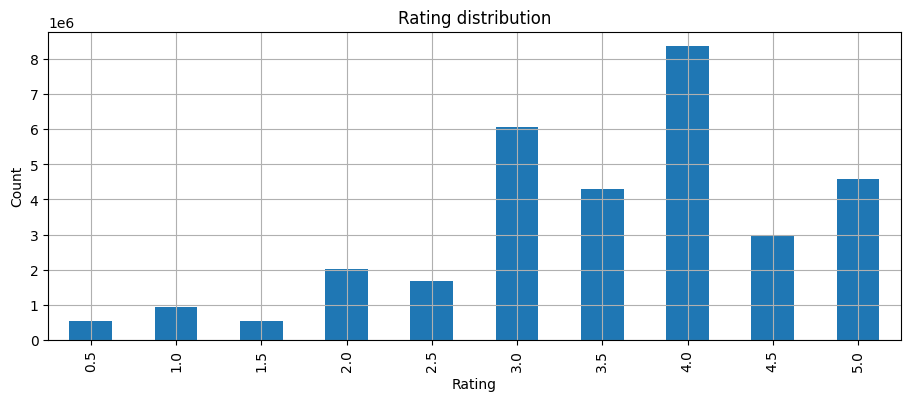

,title,genres,size,mean
movieId,,,,
318,"Shawshank Redemption, The (1994)",Crime|Drama,102929,4.404614
356,Forrest Gump (1994),Comedy|Drama|Romance|War,100296,4.052744
296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,98409,4.196969
2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,93808,4.156436
593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,90330,4.148367
260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,85010,4.099823
2959,Fight Club (1999),Action|Crime|Drama|Thriller,77332,4.228780
480,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller,75233,3.698623
527,Schindler's List (1993),Drama|War,73849,4.236990


,title,size,mean
movieId,,,
171011,Planet Earth II (2016),1956,4.446830
159817,Planet Earth (2006),2948,4.444369
170705,Band of Brothers (2001),2811,4.426538
318,"Shawshank Redemption, The (1994)",102929,4.404614
171495,Cosmos,615,4.330081
858,"Godfather, The (1972)",66440,4.317030
202439,Parasite (2019),11670,4.312253
179135,Blue Planet II (2017),1163,4.300086
198185,Twin Peaks (1989),1140,4.298684


Global mean rating: 3.540395736694336


In [8]:
ratings.rating.value_counts().sort_index().plot.bar(title='Rating distribution', xlabel='Rating', ylabel='Count'); plt.show()
item_stats = ratings.groupby('movieId').rating.agg(['size','mean','std']).join(movies.set_index('movieId'))
display(item_stats.nlargest(15, 'size')[['title','genres','size','mean']])
display(item_stats[item_stats['size'] >= 100].nlargest(15,'mean')[['title','size','mean']])
print('Global mean rating:', float(ratings.rating.mean()))

**Вывод.** Средняя оценка — 3,54. У «Побега из Шоушенка» больше всего оценок: 102 929. В каталоге есть также сериалы и документальные проекты.

## 8. Жанры и метаданные

Оцениваем признаки для рекомендаций по содержанию.

,catalog_movies,ratings
genre,,
Drama,34175,13973271.0
Comedy,23124,11206926.0
Action,9668,9665213.0
Thriller,11823,8679464.0
Adventure,5402,7590522.0
Sci-Fi,4907,5717337.0
Romance,10369,5524615.0
Crime,6976,5373051.0
Fantasy,3851,3702759.0


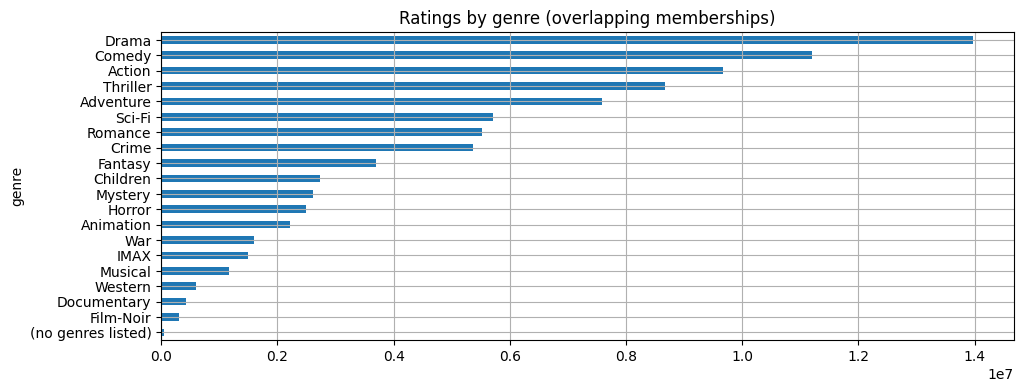

Titles without parsed year: 771


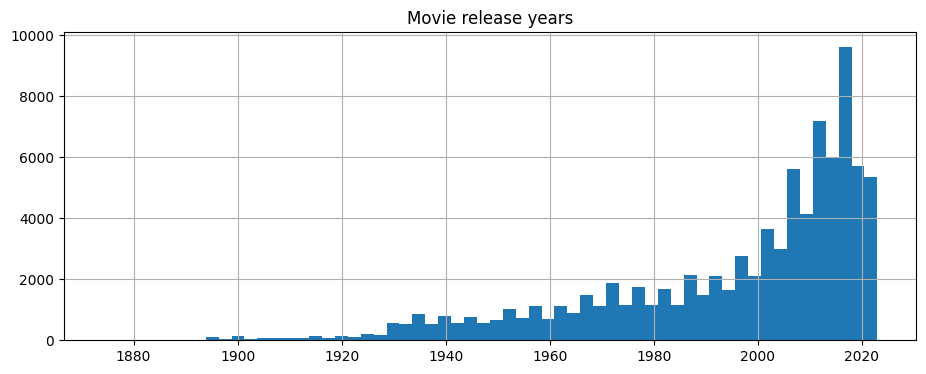

Movies with tags: 51323 Users providing tags: 15848
Rated movie tag coverage: 0.5705182869054387


,tag_count
tag_clean,
sci-fi,11457
atmospheric,10088
action,9344
comedy,9275
funny,8088
surreal,7480
visually appealing,7253
based on a book,6733
twist ending,6600


,events,mean_rating
genre,,
Film-Noir,304710.0,3.915774
War,1594110.0,3.791699
Crime,5373051.0,3.691771
Documentary,427353.0,3.691182
Drama,13973271.0,3.682454
Mystery,2615322.0,3.673103
Animation,2214562.0,3.615332
Western,596654.0,3.600175
IMAX,1494179.0,3.593312


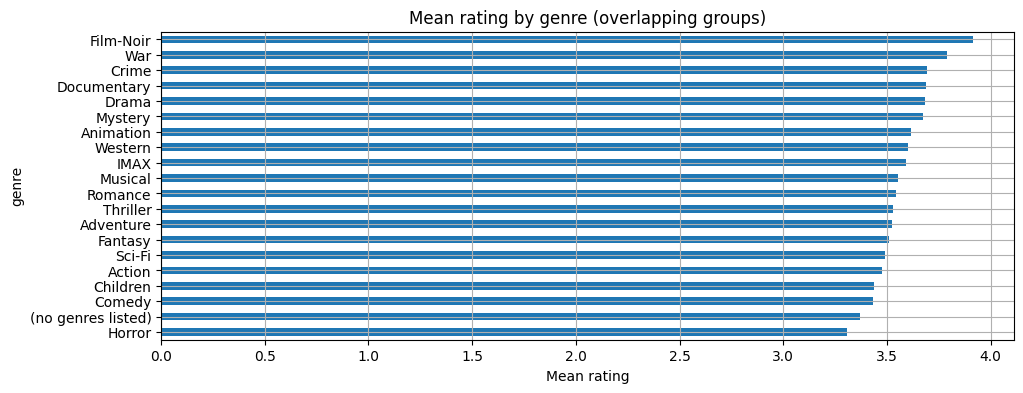

In [9]:
genre_rows = movies.assign(genre=movies.genres.str.split('|')).explode('genre')
genre_stats = genre_rows.groupby('genre').size().to_frame('catalog_movies')
genre_stats['ratings'] = genre_rows.assign(n=genre_rows.movieId.map(item_counts).fillna(0)).groupby('genre').n.sum()
display(genre_stats.sort_values('ratings', ascending=False))
genre_stats.ratings.sort_values().plot.barh(title='Ratings by genre (overlapping memberships)'); plt.show()
years = pd.to_numeric(movies.title.str.extract(r'\((\d{4})\)$', expand=False), errors='coerce')
print('Titles without parsed year:', years.isna().sum())
years.hist(bins=60); plt.title('Movie release years'); plt.show()
print('Movies with tags:', tags.movieId.nunique(), 'Users providing tags:', tags.userId.nunique())
print('Rated movie tag coverage:', item_counts.index.isin(tags.movieId.unique()).mean())
valid_tags = tags.loc[tags['tag_clean'].ne('')]
display(valid_tags['tag_clean'].str.lower().value_counts().head(20).to_frame('tag_count'))
# Средняя по событиям: каждый рейтинг имеет одинаковый вес.
item_rating_sums = ratings.groupby('movieId')['rating'].sum()
genre_features = genre_rows.assign(
    n=genre_rows['movieId'].map(item_counts).fillna(0),
    rating_sum=genre_rows['movieId'].map(item_rating_sums).fillna(0))
genre_means = genre_features.groupby('genre').agg(events=('n', 'sum'), rating_sum=('rating_sum', 'sum'))
genre_means['mean_rating'] = genre_means['rating_sum'] / genre_means['events']
display(genre_means[['events', 'mean_rating']].sort_values('mean_rating', ascending=False))
genre_means['mean_rating'].sort_values().plot.barh(title='Mean rating by genre (overlapping groups)', xlabel='Mean rating')
plt.show()


**Вывод.** По числу оценок лидируют Drama, Comedy и Action. Наибольшие средние у Film-Noir (3,92), War (3,79) и Crime (3,69); жанры пересекаются. Теги покрывают 57,05% оценённых объектов; год не извлечён у 771 записи.

## 9. Время и холодный старт

Делим данные по времени и измеряем холодный старт.

UTC range: 1995-01-09 11:46:44+00:00 2023-10-13 02:29:07+00:00


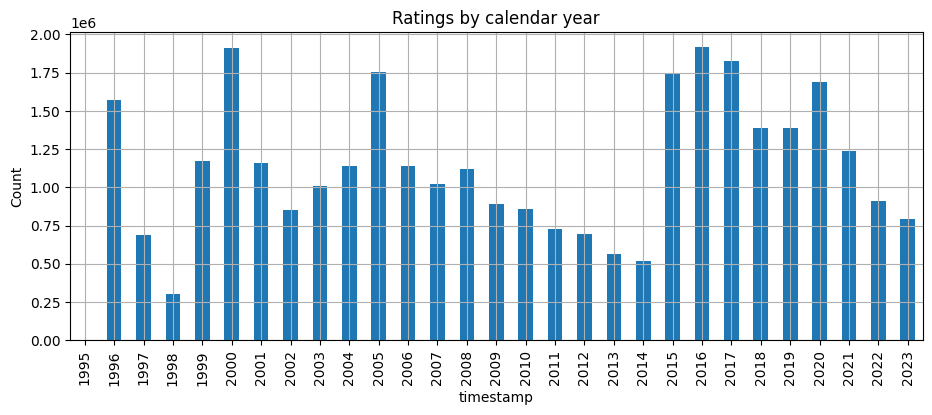

,split,rows,from_utc,to_utc,new_user_event_share,new_item_event_share
0,train,25600163,1995-01-09 11:46:44+00:00,2018-10-03 07:21:40+00:00,0.000000,0.000000
1,validation,3200020,2018-10-03 07:21:45+00:00,2020-11-05 19:45:33+00:00,0.821373,0.061575
2,test,3200021,2020-11-05 19:45:35+00:00,2023-10-13 02:29:07+00:00,0.856694,0.138057


Training tags available by cutoff: 893500


In [10]:
dates = pd.to_datetime(ratings.timestamp, unit='s', utc=True)
print('UTC range:', dates.min(), dates.max())
dates.dt.year.value_counts().sort_index().plot.bar(title='Ratings by calendar year', ylabel='Count'); plt.show()
t1, t2 = ratings.timestamp.quantile([.8,.9]).astype('int64')
train_mask = ratings.timestamp <= t1
val_mask = (ratings.timestamp > t1) & (ratings.timestamp <= t2)
test_mask = ratings.timestamp > t2
train_users = ratings.loc[train_mask,'userId'].unique()
train_items = ratings.loc[train_mask,'movieId'].unique()
rows=[]
for name, mask in [('train',train_mask),('validation',val_mask),('test',test_mask)]:
    part=ratings.loc[mask]
    rows.append({'split':name,'rows':len(part),'from_utc':pd.to_datetime(part.timestamp.min(),unit='s',utc=True), 'to_utc':pd.to_datetime(part.timestamp.max(),unit='s',utc=True), 'new_user_event_share':(~part.userId.isin(train_users)).mean(),'new_item_event_share':(~part.movieId.isin(train_items)).mean()})
split_report = pd.DataFrame(rows); display(split_report)
assert sum(x['rows'] for x in rows) == len(ratings)
print('Training tags available by cutoff:', int((tags.timestamp <= t1).sum()))
assert ratings.loc[train_mask, 'timestamp'].max() < ratings.loc[val_mask, 'timestamp'].min()
assert ratings.loc[val_mask, 'timestamp'].max() < ratings.loc[test_mask, 'timestamp'].min()
assert not (train_mask & val_mask | train_mask & test_mask | val_mask & test_mask).any()


**Вывод.** В тесте 85,67% событий от новых пользователей и 13,81% с новыми фильмами. Персонализацию нужно проверять отдельно на знакомых пользователях и фильмах. Новизна определяется относительно train по любым оценкам. Timestamp — время оценки; дата добавления фильма в каталог неизвестна.

## 10. Средняя оценка и число оценок фильма

Проверяем связь средней оценки фильма с числом наблюдений.

,movies,median_mean,p10,p90,perfect_mean_share
group,,,,,
1–4,40548,3.000000,1.500000,4.000000,0.035637
5–19,20534,3.045455,2.200000,3.666667,0.000000
20–99,11159,3.181818,2.517857,3.652174,0.000000
100–999,7794,3.309821,2.594947,3.773568,0.000000
1000+,4397,3.472853,2.745908,3.944034,0.000000


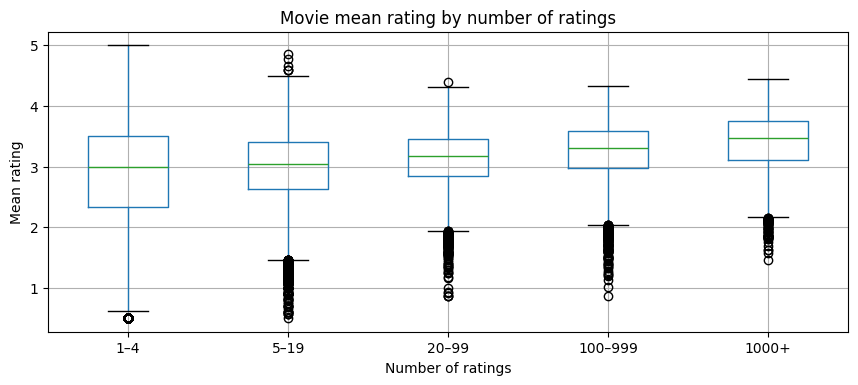

Spearman correlation: 0.1549031883043511


In [11]:
support = item_stats[['size','mean']].copy()
support['group'] = pd.cut(support['size'], [0,4,19,99,999,float('inf')], labels=['1–4','5–19','20–99','100–999','1000+'])
support_table = support.groupby('group', observed=True).agg(movies=('mean','size'), median_mean=('mean','median'), p10=('mean',lambda x:x.quantile(.1)), p90=('mean',lambda x:x.quantile(.9)), perfect_mean_share=('mean',lambda x:x.eq(5).mean()))
display(support_table)
support.boxplot(column='mean', by='group', figsize=(10, 4))
plt.suptitle('')
plt.title('Movie mean rating by number of ratings')
plt.xlabel('Number of ratings')
plt.ylabel('Mean rating')
plt.show()
mean_count_corr = support['size'].rank().corr(support['mean'].rank())
print('Spearman correlation:', mean_count_corr)


**Вывод.** Корреляция Спирмена между числом оценок и средней — 0,155. Среди фильмов с 1–4 оценками 3,56% имеют среднюю 5. Порог 100 используется только в описательном рейтинге.

## 11. Различия в оценках пользователей

Проверяем различия в пользовательских средних оценках.

,user_mean_rating
count,200948.000000
mean,3.704369
std,0.486573
min,0.500000
10%,3.111111
50%,3.725000
90%,4.293103
max,5.000000


,users,median_mean,median_std
activity,,,
20–49,72604,3.777778,0.906962
50–199,86147,3.768041,0.887803
200–999,38576,3.577959,0.890965
1000+,3621,3.290801,0.889009


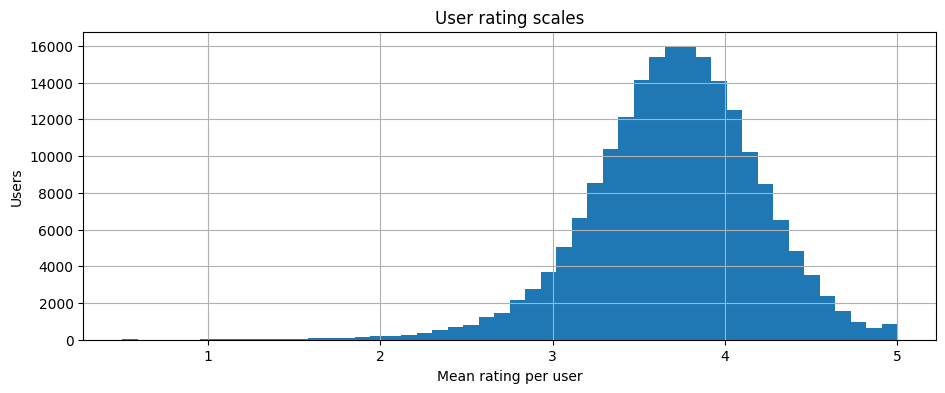

In [12]:
user_stats = ratings.groupby('userId').rating.agg(['size','mean','std'])
display(user_stats['mean'].describe(percentiles=[.1,.5,.9]).to_frame('user_mean_rating'))
user_stats['activity'] = pd.cut(user_stats['size'],[0,49,199,999,float('inf')],labels=['20–49','50–199','200–999','1000+'])
display(user_stats.groupby('activity',observed=True).agg(users=('mean','size'),median_mean=('mean','median'),median_std=('std','median')))
user_stats['mean'].hist(bins=50); plt.xlabel('Mean rating per user'); plt.ylabel('Users'); plt.title('User rating scales'); plt.show()


**Вывод.** 10-й, 50-й и 90-й процентили пользовательских средних — 3,11 / 3,72 / 4,29. Различия могут отражать шкалу оценивания и выбор фильмов.

## 12. Сравнение временных частей

Проверяем различия между обучением, валидацией и тестом.

,ratings,users,movies,mean_rating,positive_share,train_catalog_event_share,median_events_per_user
split,,,,,,,
train,25600163,170491,50977,3.531870,0.498387,1.000000,70.0
validation,3200020,22919,54803,3.589028,0.505462,0.938425,67.0
test,3200021,22252,63300,3.559969,0.488109,0.861943,66.0


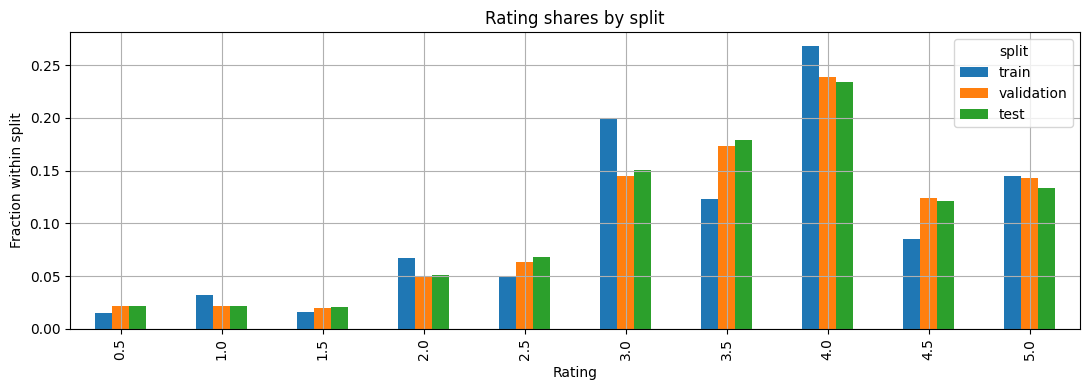

Activity measured within each period; periods have different durations.


In [13]:
# Столбцы для группового сравнения периодов.
comparison = ratings.assign(
    split=pd.cut(ratings['timestamp'], bins=[float('-inf'), t1, t2, float('inf')],
                 labels=['train', 'validation', 'test']),
    positive=ratings['rating'].ge(4),
    known_item=ratings['movieId'].isin(train_items)
)
shift = comparison.groupby('split', observed=True).agg(
    ratings=('rating', 'size'),
    users=('userId', 'nunique'),
    movies=('movieId', 'nunique'),
    mean_rating=('rating', 'mean'),
    positive_share=('positive', 'mean'),
    train_catalog_event_share=('known_item', 'mean')
)
activity = comparison.groupby(['split', 'userId'], observed=True).size()
shift['median_events_per_user'] = activity.groupby(level='split', observed=True).median()
display(shift)
distributions = pd.crosstab(comparison['rating'], comparison['split'], normalize='columns')
distributions.plot.bar(title='Rating shares by split', ylabel='Fraction within split', xlabel='Rating')
plt.tight_layout()
plt.show()
print('Activity measured within each period; periods have different durations.')


**Вывод.** Средние train / validation / test — 3,53 / 3,59 / 3,56; доли оценок ≥ 4 — 49,84% / 50,55% / 48,81%. Активность измерена за периоды разной длины.

## 13. Группа для оценки персонализации

Считаем группу для проверки персонализации без холодного старта.

In [14]:
warm_rows=[]
for name, mask in [('validation',val_mask),('test',test_mask)]:
    part=ratings.loc[mask]
    known_user=part.userId.isin(train_users)
    known_item=part.movieId.isin(train_items)
    warm=known_user & known_item
    positive=part.rating.ge(4)
    warm_positive=part.loc[warm & positive]
    users=warm_positive.groupby('userId').size()
    warm_rows.append({'split':name,'all_events':len(part),'known_user_known_item_events':int(warm.sum()),'warm_event_share':warm.mean(),'warm_positive_events':len(warm_positive),'eligible_users':len(users),'median_relevant_movies':users.median(),'eligible_share_of_period_users':len(users)/part.userId.nunique()})
warm_report=pd.DataFrame(warm_rows).set_index('split'); display(warm_report)
assert warm_report.eligible_users.gt(0).all()
# There are no repeated user–movie pairs, so these target films were not rated by the user in train.
assert not ratings.duplicated(['userId','movieId']).any()
print('Positive target: rating >= 4. Known user/item: observed in train. Targets are unique unseen pairs.')


,all_events,known_user_known_item_events,warm_event_share,warm_positive_events,eligible_users,median_relevant_movies,eligible_share_of_period_users
split,,,,,,,
validation,3200020,480907,0.150282,193119,6428,14.0,0.280466
test,3200021,312952,0.097797,119269,4310,11.0,0.193690


Positive target: rating >= 4. Known user/item: observed in train. Targets are unique unseen pairs.


**Вывод.** При обучении только на train: 6 428 подходящих пользователей в validation, 4 310 в test. В тесте 119 269 положительных целей (оценка ≥ 4), медиана — 11 на пользователя. Знакомство определено по любым оценкам train; положительная история проверяется отдельно ниже.

## 14. Связи таблиц и текстовые пропуски

Проверяем согласованность идентификаторов и риск неоднозначного объединения таблиц.

In [15]:
integrity = pd.Series({
    'duplicate_tag_rows': tags[['userId','movieId','tag','timestamp']].duplicated().sum(),
    'duplicate_links_movieId': links['movieId'].duplicated().sum(),
    'duplicate_nonnull_imdbId': links['imdbId'].dropna().duplicated().sum(),
    'duplicate_nonnull_tmdbId': links['tmdbId'].dropna().duplicated().sum(),
    'tags_movie_not_in_catalog': (~tags['movieId'].isin(movies['movieId'])).sum(),
    'tags_user_not_in_ratings': (~tags['userId'].isin(user_counts.index)).sum(),
    'links_movie_not_in_catalog': (~links['movieId'].isin(movies['movieId'])).sum(),
    'catalog_movie_not_in_links': (~movies['movieId'].isin(links['movieId'])).sum(),
    'blank_tag_text_after_strip': tags['tag_clean'].eq('').sum(),
    'literal_NA_tags': tags['tag'].eq('NA').sum(),
    'literal_null_tags': tags['tag'].eq('null').sum()
})
display(integrity.to_frame('count'))
display(links.loc[links['tmdbId'].notna() & links['tmdbId'].duplicated(keep=False)].head(10))
assert integrity['duplicate_links_movieId'] == 0
assert integrity['tags_movie_not_in_catalog'] == 0


,count
duplicate_tag_rows,0
duplicate_links_movieId,0
duplicate_nonnull_imdbId,0
duplicate_nonnull_tmdbId,36
tags_movie_not_in_catalog,0
tags_user_not_in_ratings,0
links_movie_not_in_catalog,0
catalog_movie_not_in_links,0
blank_tag_text_after_strip,6
literal_NA_tags,16


column,movieId,imdbId,tmdbId
845,864,114936,132641.0
874,895,105729,79782.0
2587,2679,124555,84198.0
4138,4241,266860,10991.0
5157,5264,250305,15028.0
5562,5672,313487,12600.0
5892,6003,290538,4912.0
6654,6776,282674,19666.0
7272,7396,70644,133919.0
9478,31026,98090,69234.0


**Вывод.** Ссылки между таблицами согласованы; полных дублей тегов и повторных movieId в links нет. В tmdbId найдено 36 повторных непустых значений: этот ключ не уникален. Теги NA (16) и null (1) не являются пропусками.

## 15. Длительность пользовательской истории

Измеряем длину истории во времени и раскладываем тест на непересекающиеся группы холодного старта.

,span_days
count,200948.000000
mean,259.117871
std,822.072529
min,0.000000
10%,0.004838
50%,0.065289
90%,708.981725
99%,4434.721153
max,9515.140428


Users whose observed ratings span <= 24 hours: 0.5878585504707685


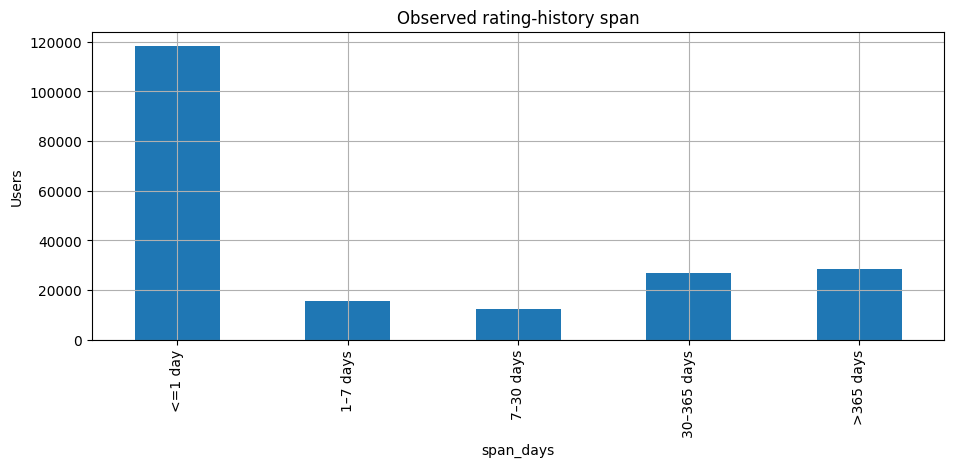

item_seen_in_train,False,True
user_seen_in_train,,
False,296156,2445284
True,145629,312952


item_seen_in_train,False,True
user_seen_in_train,,
False,0.092548,0.764146
True,0.045509,0.097797


In [16]:
user_time = ratings.groupby('userId').agg(first=('timestamp','min'),last=('timestamp','max'),ratings=('rating','size'))
user_time['span_days'] = (user_time['last'] - user_time['first']) / 86400
span_stats = user_time['span_days'].describe(percentiles=[.1,.5,.9,.99])
display(span_stats.to_frame('span_days'))
short_span_share = user_time['span_days'].le(1).mean()
print('Users whose observed ratings span <= 24 hours:', short_span_share)
pd.cut(user_time['span_days'], [-1,1,7,30,365,float('inf')],
       labels=['<=1 day','1–7 days','7–30 days','30–365 days','>365 days']).value_counts(sort=False).plot.bar(title='Observed rating-history span', ylabel='Users')
plt.show()
test = ratings.loc[test_mask]
cold_segments = pd.crosstab(test['userId'].isin(train_users), test['movieId'].isin(train_items))
cold_segments.index.name='user_seen_in_train'
cold_segments.columns.name='item_seen_in_train'
display(cold_segments)
display(cold_segments / len(test))
assert cold_segments.to_numpy().sum() == len(test)


**Вывод.** Медианная длительность истории оценок — 94 минуты. У 58,79% пользователей оценки укладываются в 24 часа. Это время выставления оценок, а не длительность просмотров.

## 16. Положительная обучающая история

Проверяем размер группы оценки при разных порогах положительного рейтинга и минимальной длине положительной истории.

,split,positive_threshold,min_positive_train_history,eligible_users,relevant_events,median_relevant_per_user
0,validation,3.5,1,6537,287044,19.0
1,test,3.5,1,4407,184366,17.0
2,validation,3.5,5,6468,280270,19.0
3,test,3.5,5,4367,180785,17.0
4,validation,3.5,20,6172,264051,19.0
5,test,3.5,20,4210,170330,16.0
6,validation,4.0,1,6410,189548,14.0
7,test,4.0,1,4295,117555,11.0
8,validation,4.0,5,6321,183977,13.0
9,test,4.0,5,4251,114724,11.0


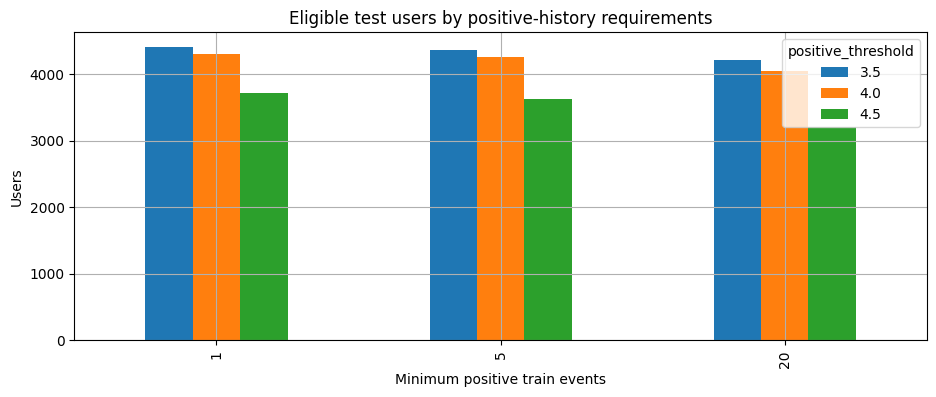

In [17]:
sensitivity_rows = []
for threshold in [3.5, 4.0, 4.5]:
    train_positive = ratings.loc[train_mask & ratings['rating'].ge(threshold)]
    positive_user_support = train_positive.groupby('userId').size()
    positive_item_support = train_positive.groupby('movieId').size()
    for min_history in [1, 5, 20]:
        supported_users = positive_user_support.loc[positive_user_support.ge(min_history)].index
        for split_name, mask in [('validation',val_mask),('test',test_mask)]:
            relevant = ratings.loc[mask & ratings['rating'].ge(threshold)
                                   & ratings['userId'].isin(supported_users)
                                   & ratings['movieId'].isin(positive_item_support.index)]
            per_user = relevant.groupby('userId').size()
            sensitivity_rows.append({'split':split_name, 'positive_threshold':threshold,
                                     'min_positive_train_history':min_history,
                                     'eligible_users':per_user.size, 'relevant_events':len(relevant),
                                     'median_relevant_per_user':per_user.median()})
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)
sensitivity.loc[sensitivity['split'].eq('test')].pivot(
    index='min_positive_train_history', columns='positive_threshold', values='eligible_users'
).plot.bar(title='Eligible test users by positive-history requirements', ylabel='Users', xlabel='Minimum positive train events')
plt.show()


**Вывод.** При пороге ≥ 4 и наличии положительной истории фильма в train: 4,295 тестовых пользователей с минимум одной положительной оценкой в train, 4,251 с минимум пятью и 4,047 с минимум двадцатью. Состав тестовой группы зависит от правил обучения.

## 17. Попарные связи признаков с оценкой

Оцениваем связи train-признаков с validation-рейтингом на фиксированной выборке событий.

Validation events sampled: 200000 of 3200020 ; random_state=42


,count,mean,std,min,25%,50%,75%,max
rating,200000.0,3.588900,1.056334,0.500000,3.000000,4.000000,4.500000,5.0
user_count,35828.0,1215.343028,3140.572863,1.000000,177.000000,491.000000,1112.000000,22912.0
item_count,187830.0,13328.327221,16542.427087,1.000000,1709.000000,7232.000000,18333.000000,85040.0
user_mean,35828.0,3.533622,0.528058,1.327869,3.180224,3.542176,3.858209,5.0
item_mean,187830.0,3.589258,0.448113,0.500000,3.346687,3.685838,3.904933,5.0
release_year,199212.0,2002.389891,15.342267,1874.000000,1997.000000,2006.000000,2013.000000,2020.0


,missing_pct
rating,0.000
user_count,82.086
item_count,6.085
user_mean,82.086
item_mean,6.085
release_year,0.394


Pearson


,rating,user_count,item_count,user_mean,item_mean,release_year
rating,1.000000,-0.120726,0.195331,0.376109,0.374875,-0.059012
user_count,-0.120726,1.000000,-0.144908,-0.223954,-0.158804,-0.096688
item_count,0.195331,-0.144908,1.000000,0.133545,0.462514,-0.235812
user_mean,0.376109,-0.223954,0.133545,1.000000,0.123553,0.006841
item_mean,0.374875,-0.158804,0.462514,0.123553,1.000000,-0.141049
release_year,-0.059012,-0.096688,-0.235812,0.006841,-0.141049,1.000000


Spearman


,rating,user_count,item_count,user_mean,item_mean,release_year
rating,1.000000,-0.232241,0.215745,0.388792,0.384924,-0.062928
user_count,-0.232241,1.000000,-0.414448,-0.497448,-0.213091,0.091898
item_count,0.215745,-0.414448,1.000000,0.194394,0.515894,-0.434673
user_mean,0.388792,-0.497448,0.194394,1.000000,0.132853,-0.024241
item_mean,0.384924,-0.213091,0.515894,0.132853,1.000000,-0.148496
release_year,-0.062928,0.091898,-0.434673,-0.024241,-0.148496,1.000000


Pairwise observation counts


,rating,user_count,item_count,user_mean,item_mean,release_year
rating,200000,35828,187830,35828,187830,199212
user_count,35828,35828,30256,35828,30256,35558
item_count,187830,30256,187830,30256,187830,187190
user_mean,35828,35828,30256,35828,30256,35558
item_mean,187830,30256,187830,30256,187830,187190
release_year,199212,35558,187190,35558,187190,199212


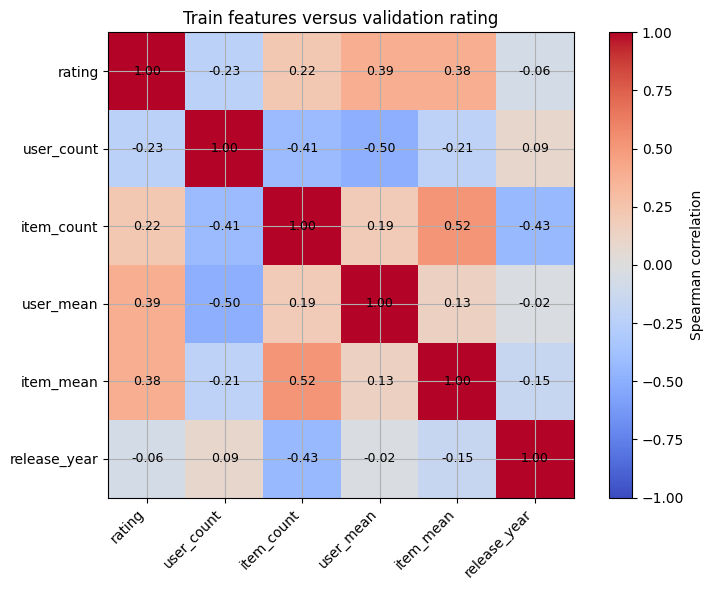

Complete cases: 30060 share of event sample: 0.1503
Scatter matrix sample: 3000 ; random_state=42; counts shown as log1p


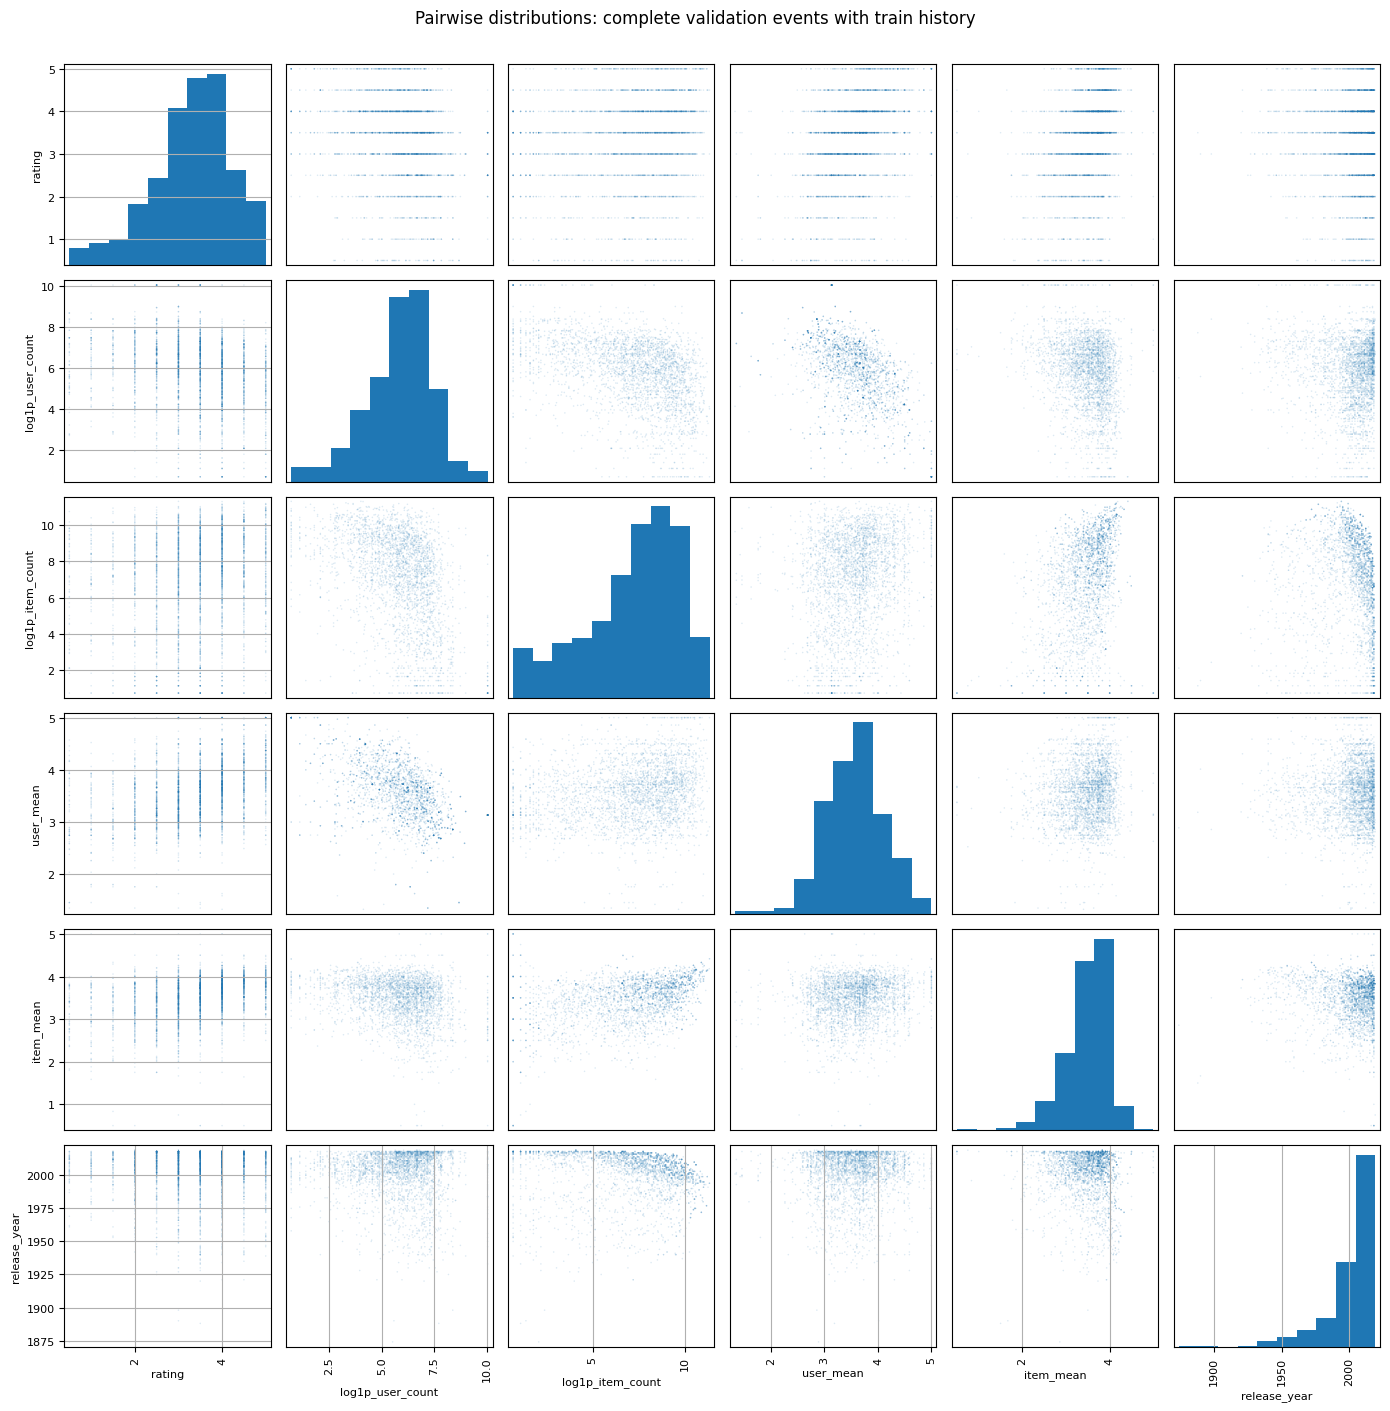

In [18]:
train_frame = ratings.loc[train_mask]
train_user_features = train_frame.groupby('userId')['rating'].agg(['size','mean'])
train_item_features = train_frame.groupby('movieId')['rating'].agg(['size','mean'])
validation_sample = ratings.loc[val_mask].sample(n=min(200_000,int(val_mask.sum())),random_state=42)
features = pd.DataFrame({
    'rating':validation_sample['rating'],
    'user_count':validation_sample['userId'].map(train_user_features['size']),
    'item_count':validation_sample['movieId'].map(train_item_features['size']),
    'user_mean':validation_sample['userId'].map(train_user_features['mean']),
    'item_mean':validation_sample['movieId'].map(train_item_features['mean']),
    'release_year':validation_sample['movieId'].map(movies_clean.set_index('movieId')['release_year'])
}).astype(float)
# Агрегаты только из train; NaN у новых пользователей/фильмов не заменяются нулевыми средними.
print('Validation events sampled:', len(features), 'of', int(val_mask.sum()), '; random_state=42')
display(features.describe().T)
display(features.isna().mean().mul(100).to_frame('missing_pct'))
pearson = features.corr(method='pearson')
spearman = features.corr(method='spearman')
observed = features.notna().astype('int64')
pair_counts = observed.T.dot(observed)
print('Pearson'); display(pearson)
print('Spearman'); display(spearman)
print('Pairwise observation counts'); display(pair_counts)

fig, ax = plt.subplots(figsize=(8,6))
heatmap = ax.imshow(spearman, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(features.columns)),labels=features.columns,rotation=45,ha='right')
ax.set_yticks(range(len(features.columns)),labels=features.columns)
for row in range(len(features.columns)):
    for col in range(len(features.columns)):
        ax.text(col,row,f'{spearman.iloc[row,col]:.2f}',ha='center',va='center',fontsize=9)
fig.colorbar(heatmap, ax=ax, label='Spearman correlation')
ax.set_title('Train features versus validation rating')
plt.tight_layout(); plt.show()

complete = features.dropna()
plot_sample = complete.sample(n=min(3000,len(complete)),random_state=42).copy()
# Логарифм счётчиков делает длинные хвосты видимыми; таблицы корреляций выше используют исходные значения.
from math import log1p
plot_sample['user_count'] = plot_sample['user_count'].map(log1p)
plot_sample['item_count'] = plot_sample['item_count'].map(log1p)
plot_sample = plot_sample.rename(columns={'user_count':'log1p_user_count','item_count':'log1p_item_count'})
print('Complete cases:',len(complete),'share of event sample:',len(complete)/len(features))
print('Scatter matrix sample:',len(plot_sample),'; random_state=42; counts shown as log1p')
axes = pd.plotting.scatter_matrix(plot_sample,figsize=(14,14),diagonal='hist',alpha=.15,s=5)
for axis in axes.ravel():
    axis.set_xlabel(axis.get_xlabel(),fontsize=8)
    axis.set_ylabel(axis.get_ylabel(),fontsize=8)
plt.suptitle('Pairwise distributions: complete validation events with train history',y=1.005)
plt.tight_layout(); plt.show()
assert train_frame['timestamp'].max() < validation_sample['timestamp'].min()


**Вывод.** На 200 000 validation-событий корреляции Спирмена рейтинга со средней пользователя и фильма из train составляют 0.389 и 0.385. Это кандидаты в признаки; связи описательные, число доступных пар различается. Полных строк — 30,060 (15.03%); scatter matrix построена по 3 000 из них и характеризует только объекты с известными признаками. Выборка равномерна по событиям, поэтому активные пользователи представлены чаще.

**Применение результатов на следующем этапе**

| Результат EDA | Решение для модели и проверки |
|---|---|
| Разреженность 99,81%; отсутствие оценки не равно отрицательному отзыву | Использовать разреженные взаимодействия. Сначала сравнить популярность и персональную модель; не заполнять неизвестные рейтинги нулями. |
| 1% оценённых фильмов получает 54,88% оценок | Помимо NDCG@10 и Recall@10 измерять покрытие каталога и качество на редких фильмах. |
| 6 пустых тегов, неизвестные жанры/годы, 124 отсутствующих tmdbId | Использовать подготовленные tags_clean, movies_clean, links_clean. Объединять по movieId; не придумывать внешние ID. |
| Train-средние пользователя и фильма связаны с validation-рейтингом | Проверить модель с пользовательским и предметным смещением. Все агрегаты считать только по обучающему периоду. |
| 85,67% тестовых событий от новых пользователей | Отдельно оценивать четыре группы знакомых/новых пользователей и фильмов. Для холодного старта предусмотреть популярность и жанры. |
| Размер группы зависит от положительного порога и истории | Зафиксировать порог ≥ 4 как исходный вариант, сравнить 3,5 и 4,5 на validation. Публиковать число подходящих пользователей и тестовых целей. |
| Медианная история выставления оценок — 94 минуты | Не трактовать timestamp как историю просмотров. При оценке исключать уже оценённые фильмы; теги брать только до границы обучения. |
| Каталог содержит сериалы; данные заканчиваются в 2023 году | При отборе только фильмов уточнить тип объекта. Полученные результаты относятся к данным до октября 2023 года. |

Настройки выбирать на validation; тест использовать для итогового сравнения. При переобучении на train+validation пересчитать признаки, доступный каталог и группы холодного старта. Метрики моделей в этом чекпойнте ещё не измеряются. Краткие результаты анализа и выводы для рекомендательной системы собраны в [EDA_summary.pdf](EDA_summary.pdf).
